In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import getpass

engine = create_engine(f"postgresql+psycopg2://{getpass.getuser()}@localhost:5432/bank")

df = pd.read_sql("SELECT * FROM customers", engine)
sns.set_theme(style="whitegrid")
df.shape


(10000, 14)

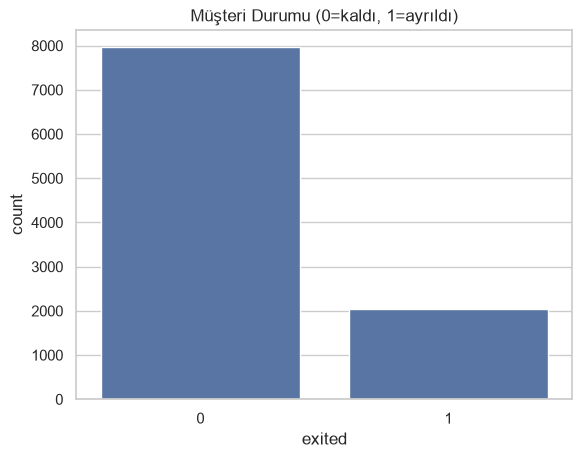

np.float64(0.2037)

In [4]:
sns.countplot(x="exited", data=df)
plt.title("Müşteri Durumu (0=kaldı, 1=ayrıldı)")
plt.show()

df["exited"].mean()

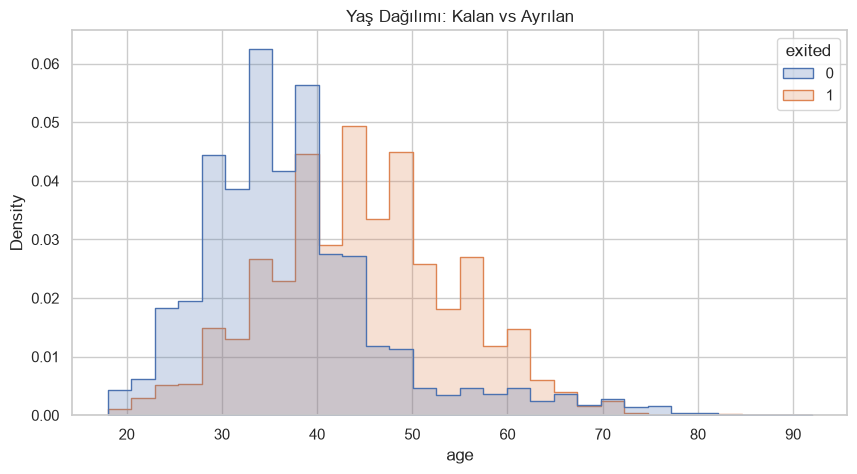

In [8]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df, x="age", hue="exited",
    bins=30, element="step", stat="density",
    common_norm=False
)
plt.title("Yaş Dağılımı: Kalan vs Ayrılan")
plt.show()


In [11]:
summary = df.groupby(df["balance"].eq(0)).agg(
    customer_count=("exited", "size"),
    churn_rate=("exited", "mean")
)
summary.index.name = "zero_balance"
summary["churn_rate_pct"] = (summary.pop("churn_rate") * 100).round(2)
summary


,customer_count,churn_rate_pct
zero_balance,,
False,6383,24.08
True,3617,13.82


Sıfır bakiye oranı: 0.3617


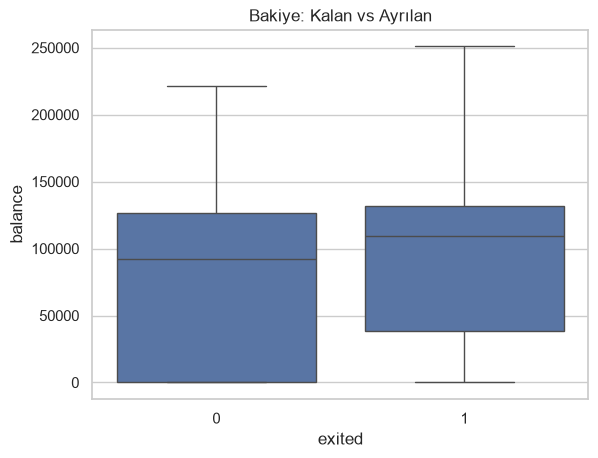

In [14]:
df["balance_zero"] = (df["balance"] == 0).astype(int)
print("Sıfır bakiye oranı:", df["balance_zero"].mean())

sns.boxplot(x="exited", y="balance", data=df)
plt.title("Bakiye: Kalan vs Ayrılan")
plt.show()

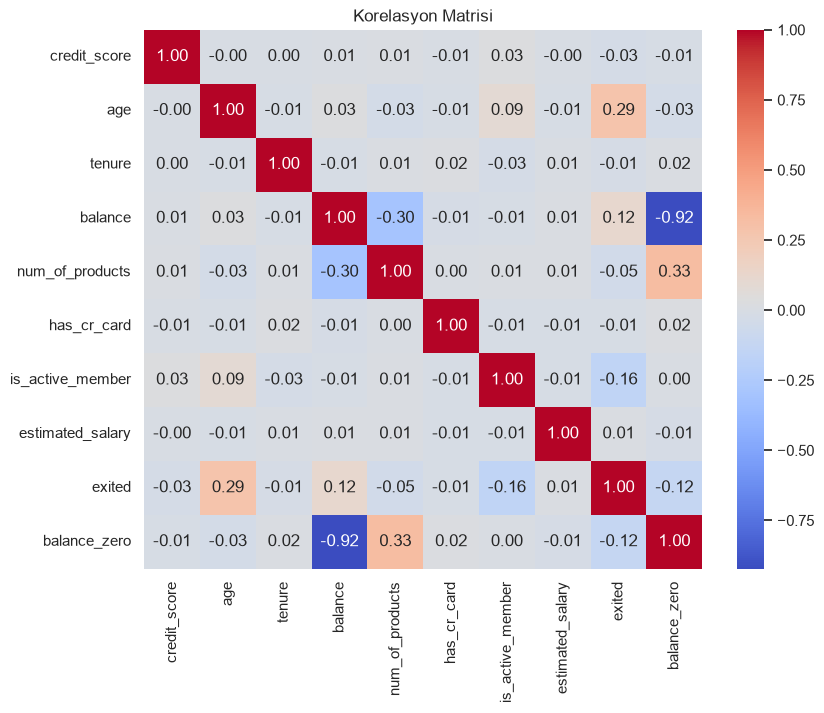

In [15]:
num = df.select_dtypes("number").drop(columns=["row_number", "customer_id"])
plt.figure(figsize=(9, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasyon Matrisi")
plt.show()